In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

In [32]:
file_path = '../data/1_raw_data_vegetal_augmente.csv'
data = pd.read_csv(file_path, sep=';')
data.head()

,chanvre 5,chanvre 15,bambou 5,bambou 15,lin 5,lin 6,lin 15,miscanthus 5,miscanthus 15,Days,...,Air occluded (%),Volumic mass (kg/m3),FS (Mpa),CS (Mpa),Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers,Absorption coefficient t=2880s rigid fibers,formulation_id,is_synthetic
0,"0,4","0,0","0,0","0,0","0,0","0,0","0,0","0,0","0,0",1,...,"3,7","2228,7","2,79","11,36",154,0,"135,27","0,0",61,0
1,"0,0","0,4","0,0","0,0","0,0","0,0","0,0","0,0","0,0",1,...,"3,6","2219,8","3,13","10,0",308,0,"135,47","0,0",55,0
2,"0,0","0,0","0,4","0,0","0,0","0,0","0,0","0,0","0,0",1,...,"3,2","2236,6000000000004","2,43","8,69",0,17,"0,0","98,93",49,0
3,"0,0","0,0","0,0","0,4","0,0","0,0","0,0","0,0","0,0",1,...,"3,3","2231,2","2,82","9,17",0,33,"0,0","89,7",36,0
4,"0,0","0,0","0,0","0,0","0,4","0,0","0,0","0,0","0,0",1,...,"3,6","2211,7","2,56","7,11",167,0,"155,27","0,0",30,0


In [33]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype
---  ------                                       --------------  -----
 0   chanvre 5                                    1216 non-null   str  
 1   chanvre 15                                   1216 non-null   str  
 2   bambou 5                                     1216 non-null   str  
 3   bambou 15                                    1216 non-null   str  
 4   lin 5                                        1216 non-null   str  
 5   lin 6                                        1216 non-null   str  
 6   lin 15                                       1216 non-null   str  
 7   miscanthus 5                                 1216 non-null   str  
 8   miscanthus 15                                1216 non-null   str  
 9   Days                                         1216 non-null   int64
 10  Slump (mm)                         

In [34]:
data.describe()

,Days,Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,formulation_id,is_synthetic
count,1216.000000,1216.000000,1216.000000,1216.000000,1216.000000
mean,32.947368,133.223684,16.578947,39.921053,0.750000
std,35.570328,108.756394,13.857607,23.157937,0.433191
min,1.000000,0.000000,0.000000,1.000000,0.000000
25%,7.000000,0.000000,0.000000,19.750000,0.750000
50%,28.000000,154.000000,17.000000,39.500000,1.000000
75%,90.000000,167.000000,27.000000,59.250000,1.000000
max,90.000000,333.000000,33.000000,80.000000,1.000000


# 2. Data Cleaning

## 2.1 Missing Values

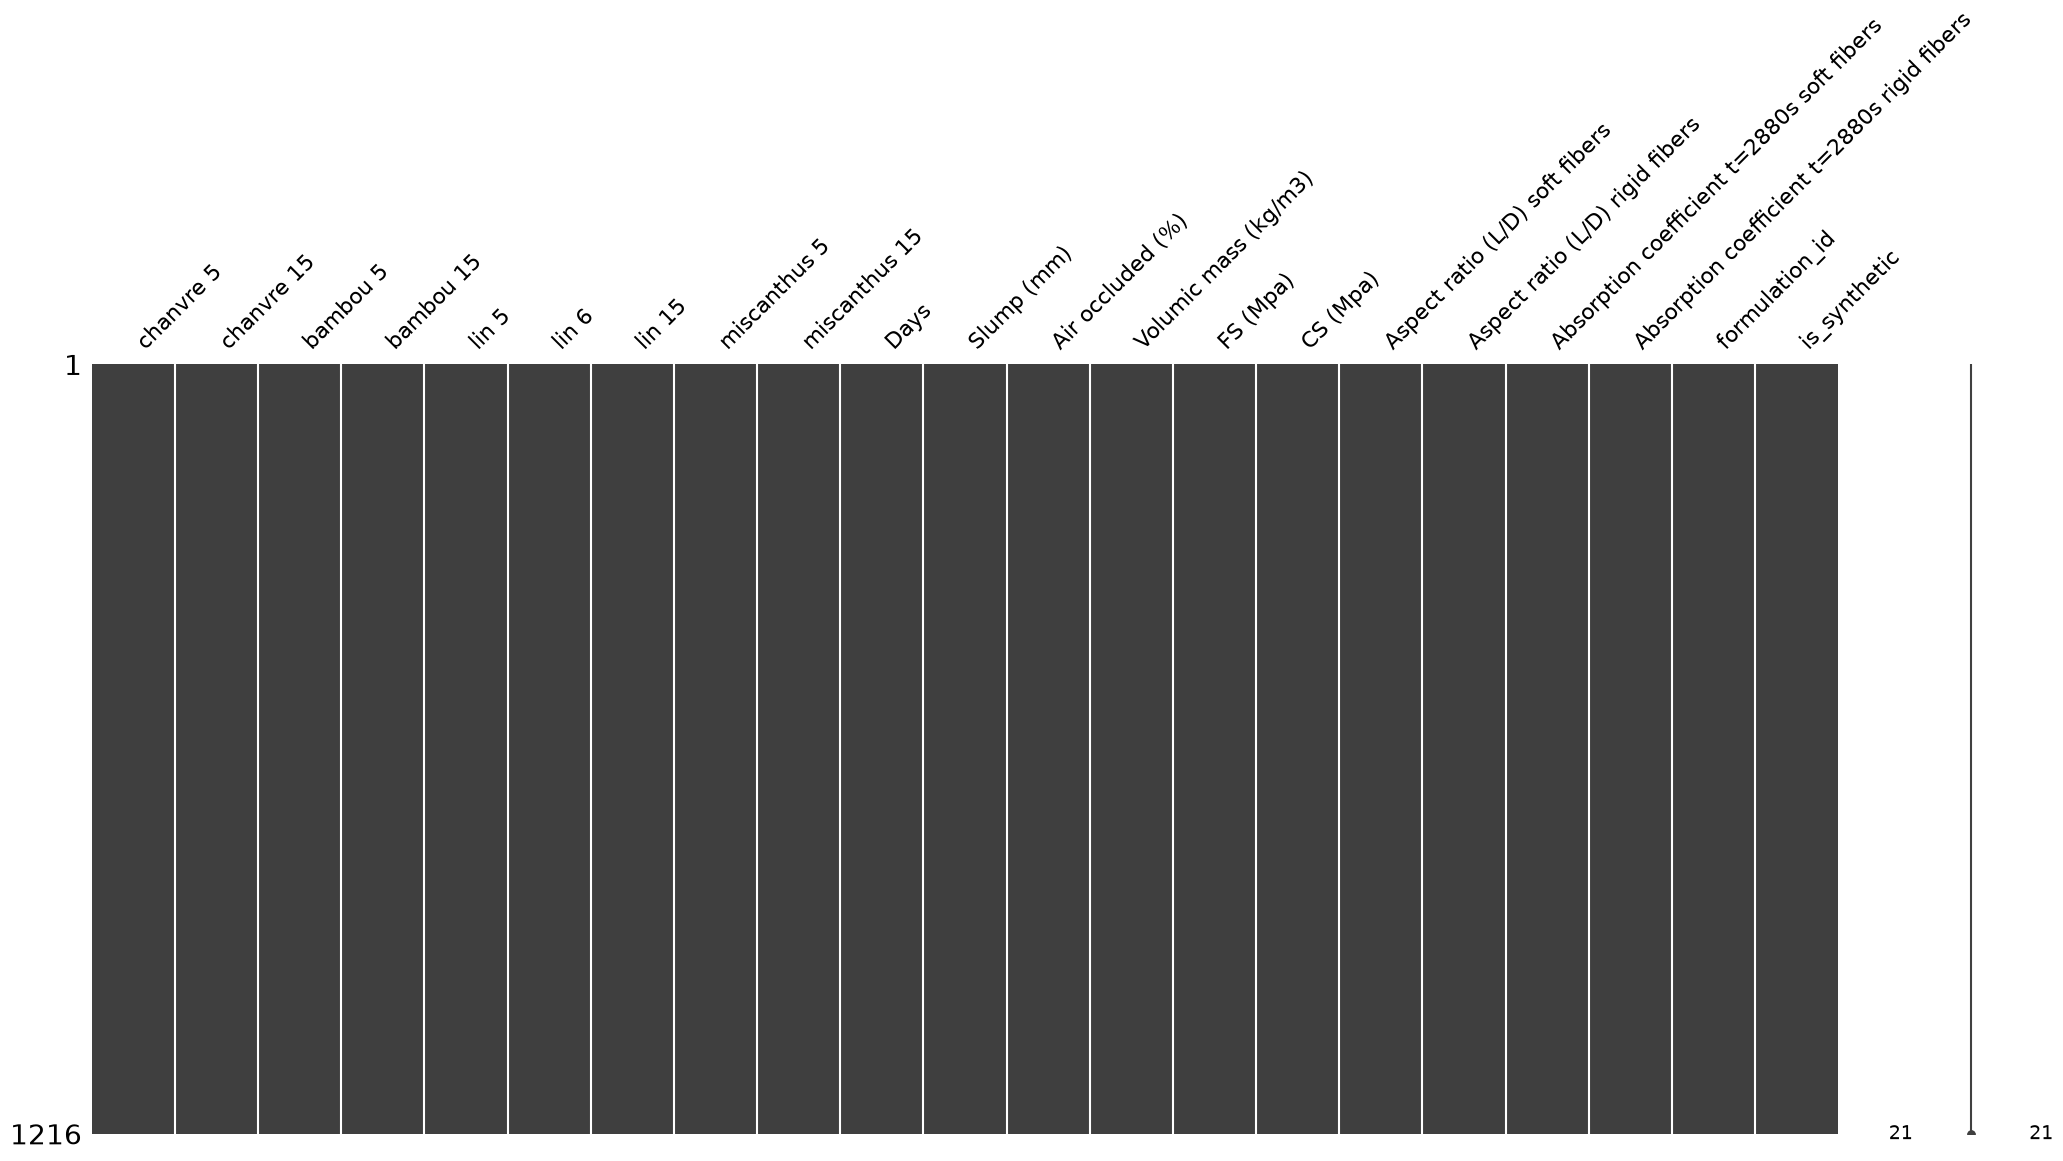

In [35]:
# Visualize missing data
msno.matrix(data)
plt.show()

In [36]:
def show_metric(data, column):
    print("=" * 50)
    print(f"{column:^50}")
    print("=" * 50)
    print(f"{'Données manquantes':<35} {data[column].isna().sum():>10}")
    print(f"{'% manquantes':<35} {round((data[column].isna().sum() / len(data)) * 100, 2):>9}%")
    print(f"{'Données disponibles':<35} {data[column].notna().sum():>10}")
    print(f"Lignes non alignées avec la colonne cible : {len([index for index, row in data.iterrows() if pd.isna(row[column]) and not pd.isna(row['Rc (MPa)'])])}")
    print("=" * 50)

show_metric(data, 'FS (Mpa)')

                     FS (Mpa)                     
Données manquantes                           0
% manquantes                              0.0%
Données disponibles                       1216
Lignes non alignées avec la colonne cible : 0


<p style="color: grey;">
The datset has no missing value for flexural strength (FS).
</p>

## 2.3 Categorical Values

<p>On convertit les valeurs catégoriels présentes en integer </p>

In [37]:

categorical_columns = data.select_dtypes(include=['object', 'string']).columns
for column in categorical_columns:
    data[column] = data[column].str.replace(',', '.')
    data[column] = pd.to_numeric(data[column])

In [38]:
data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    1216 non-null   float64
 1   chanvre 15                                   1216 non-null   float64
 2   bambou 5                                     1216 non-null   float64
 3   bambou 15                                    1216 non-null   float64
 4   lin 5                                        1216 non-null   float64
 5   lin 6                                        1216 non-null   float64
 6   lin 15                                       1216 non-null   float64
 7   miscanthus 5                                 1216 non-null   float64
 8   miscanthus 15                                1216 non-null   float64
 9   Days                                         1216 non-null   int64  
 10  Slump (mm) 

## 2.2 Contrôle de cohérence des données

In [39]:
cols_fibre = [c for c in data.columns if 'Type' in c or 'Dosage' in c or 'Aspect' in c]
print(data.loc[data['Aspect ratio (L/D) rigid fibers'] > 100, cols_fibre].drop_duplicates())


m = data['Aspect ratio (L/D) rigid fibers'] > 100
data.loc[m, 'Aspect ratio (L/D) rigid fibers'] = 0

Empty DataFrame
Columns: [Aspect ratio (L/D) soft fibers, Aspect ratio (L/D) rigid fibers]
Index: []


## 2.3 Harmonisation des unités de mesure

In [40]:
col = 'Volumic mass (kg/m3)'
data.loc[data[col] < 100, col] *= 1000   # 2.13 -> 2130 kg/m3 ; les 2228.4 restent tels quels
print(data[col].describe())              # doit aller d'environ 2100 à 2250

#Les ouliers de masse volumique nous ont permis d'identifier des erreurs de saisie à 0, nous allons donc les supprimer : 

Mv0 = data['Volumic mass (kg/m3)'] == 0
print("Lignes masse vol. = 0 :", (data['Volumic mass (kg/m3)'] == 0).sum())
print(data.loc[Mv0].filter(like='Type').drop_duplicates())   # quelles fibres/formulations
#supprimer les lignes avec masse volumique = 0
data = data.loc[~Mv0]

count    1216.000000
mean     2169.396554
std        70.754666
min      1870.970000
25%      2130.000000
50%      2177.765000
75%      2221.550000
max      2349.150000
Name: Volumic mass (kg/m3), dtype: float64
Lignes masse vol. = 0 : 0
Empty DataFrame
Columns: []
Index: []


In [41]:
print("Air = 0 :", (data['Air occluded (%)'] == 0).sum())

Air = 0 : 0


## 2.4 Outliers

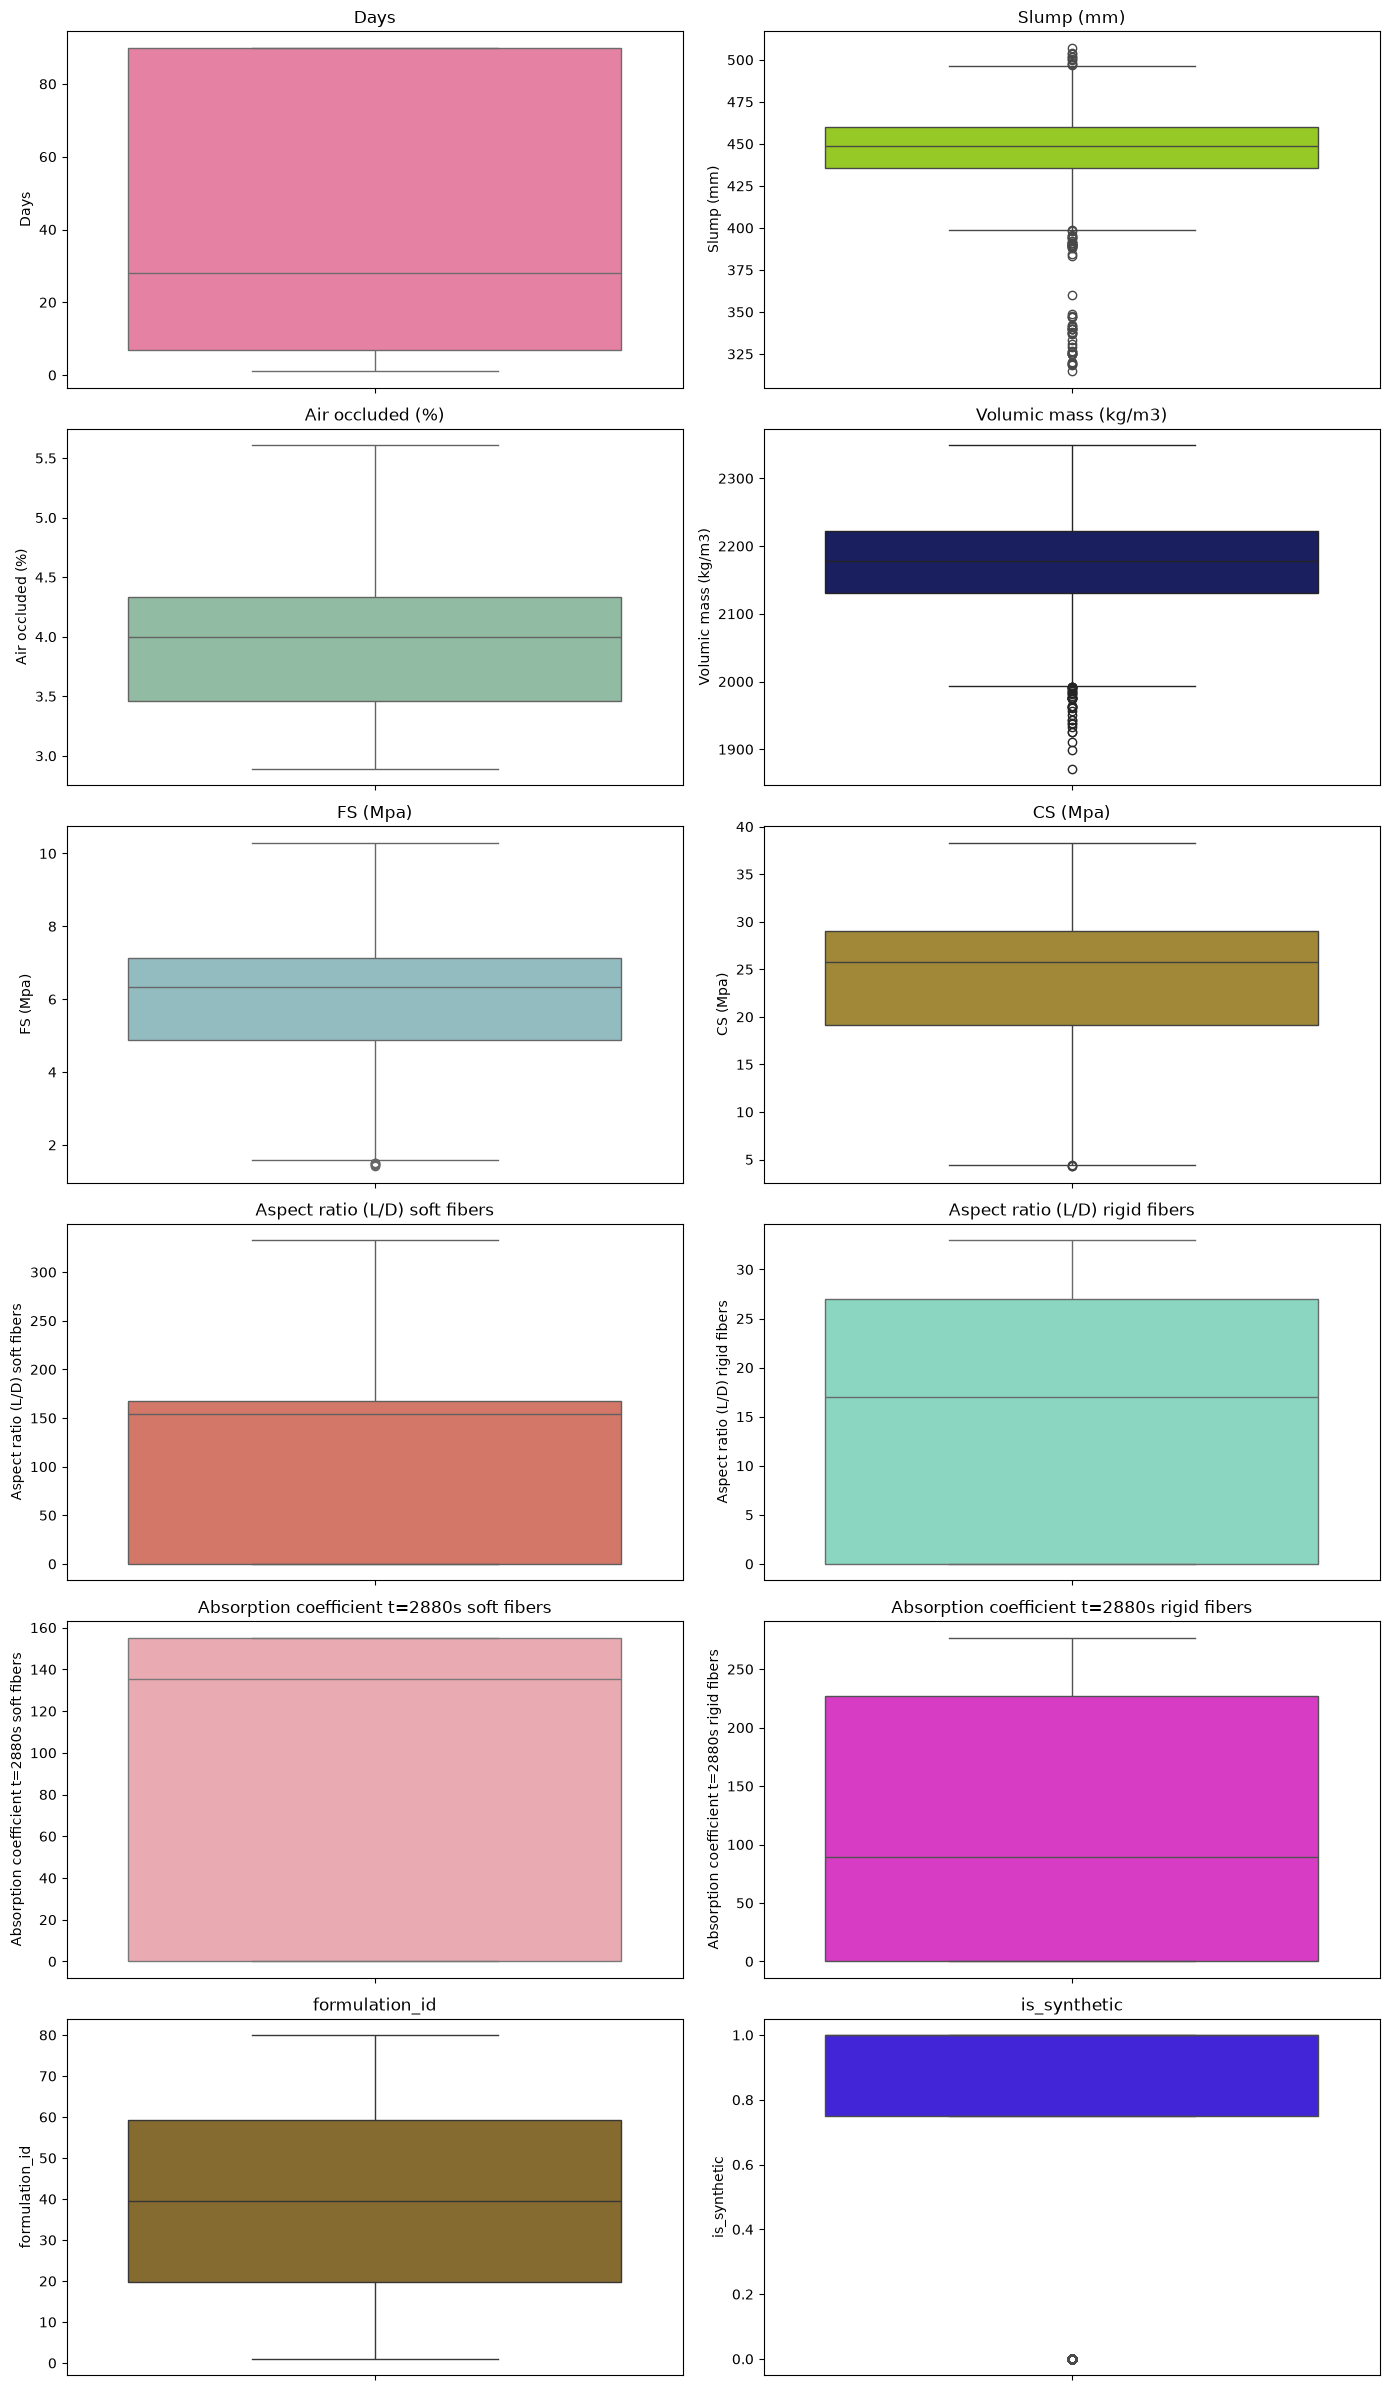

In [42]:
fiber_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 
              'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15',
              'ch.antif.', 'ch.strux']
#ne pas mettre les fiber_cols dans les colonnes numériques pour l'analyse statistique

numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
numerical_columns = [col for col in numerical_columns if col not in fiber_cols]
n = len(numerical_columns)
cols = 2
rows = (n + 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.boxplot(y=data[column], ax=axes[i], color=tuple(np.random.rand(3)))
    axes[i].set_title(column)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<p>On ne supprime pas les valeurs aberrantes du dataset car elles sont normal et correspondent à de réel valeurs importantes pour notre études</p>

## 3. CSV Export

In [43]:
#export en csv 
data.to_csv('../data/2_cleaned_data.csv', index=False)